# Notebook 07 — Proxy, Fairness and Crime Audit

I check whether the seven measures in the earlier model carry information about ethnic composition or deprivation, whether prediction errors differ across kinds of area, and whether the predictions change when crime is left out.

These are area-level checks. They do not explain causes or describe individual residents.

## Setting up

I reuse the earlier project discovery and read/save helpers. I keep the seven-feature model's local-authority folds and seed, and save this phase's outputs in a new folder.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr
from IPython.display import display

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

%matplotlib inline

project_folder = next(p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "Data/Cleaned/Wide/msoa_wide_660.csv").is_file()
    or (p / "data/cleaned/Wide/msoa_wide_660.csv").is_file())
data_folder = project_folder / ("Data" if (project_folder / "Data").is_dir() else "data")

def project_data(relative_path):
    parts = Path(relative_path).parts
    if data_folder.name == "data":
        parts = (parts[0].lower(), *parts[1:])
    return data_folder.joinpath(*parts)

expected_environment = project_folder.parent / ".venv-unit3"
if expected_environment.is_dir():
    assert Path(sys.prefix).resolve() == expected_environment.resolve(), "Select the Unit 3 environment."

def read_csv(relative):
    return pd.read_csv(project_data(relative))

output_folder = project_data("Cleaned/Fairness")
figure_folder = project_data("Cleaned/Fairness/figures")
assert not output_folder.is_symlink() and not figure_folder.is_symlink()
output_folder.mkdir(parents=True, exist_ok=True)
figure_folder.mkdir(parents=True, exist_ok=True)

def save_csv(table, filename, index=False):
    path = output_folder / filename
    assert not path.exists() and not path.is_symlink()
    with path.open("w", encoding="utf-8", newline="") as stream:
        table.to_csv(stream, index=index)
    check = pd.read_csv(path)
    expected = table.reset_index() if index else table.reset_index(drop=True)
    pd.testing.assert_frame_equal(check, expected, check_dtype=False)

def save_json(value, filename):
    path = output_folder / filename
    assert not path.exists() and not path.is_symlink()
    with path.open("w", encoding="utf-8") as stream:
        json.dump(value, stream, indent=2, ensure_ascii=False, allow_nan=False)
    assert json.loads(path.read_text(encoding="utf-8")) == value

def save_figure(figure, filename):
    allowed_figures = {
        "proxy_r2.png", "proxy_spearman_heatmap.png",
        "error_by_third_intervals.png", "crime_with_without_comparison.png",
    }
    assert filename in allowed_figures
    path = figure_folder / filename
    assert not path.is_symlink()
    if path.exists():
        assert path.is_file()
    figure.savefig(path, bbox_inches="tight")
    assert path.is_file() and path.stat().st_size > 0
    plt.show()
    plt.close(figure)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
EXPECTED_AREAS, EXPECTED_MODEL_AREAS = 660, 654
SEED, FOLDS = 42, 5
BOOTSTRAP_RESAMPLES, BOOTSTRAP_SEED = 2_000, 20261017
MORAN_PERMUTATIONS = 999
PALETTE = ["#243b53", "#c25024", "#087f8c", "#b54724"]

print(f"Notebook 07 settings: areas={EXPECTED_AREAS}, model areas={EXPECTED_MODEL_AREAS}, GroupKFold folds={FOLDS}, seed={SEED}.")
print(f"Bootstrap resamples per third: {BOOTSTRAP_RESAMPLES}, seed={BOOTSTRAP_SEED}; Moran permutations: {MORAN_PERMUTATIONS}.")

Notebook 07 settings: areas=660, model areas=654, GroupKFold folds=5, seed=42.
Bootstrap resamples per third: 2000, seed=20261017; Moran permutations: 999.


## Matching the earlier model and the six ethnic groups

I take the provisional representatives, study areas and local-authority lookup from the earlier model. The six ethnic groups follow Notebook 06: White British, Other White, Asian, Black, Mixed and Other. I combine the four non-White groups—Asian, Black, Mixed and Other—for the composition measure used in the second error split. Other White (White Irish, Gypsy or Irish Traveller, Roma and Other White) is classified as White and excluded.

In [2]:
wide = read_csv("Cleaned/Wide/msoa_wide_660.csv").sort_values("area_code").reset_index(drop=True)
assert len(wide) == EXPECTED_AREAS and wide["area_code"].is_unique
saved_05 = json.loads(project_data("Cleaned/Machine Learning/results_summary.json").read_text())

review = read_csv("Cleaned/Wide/theme_representatives_for_review.csv")
representatives = review.loc[review["decision"].eq("Provisional representative")].copy()
features = representatives["measure"].tolist()
assert len(features) == 7 and len(set(features)) == 7
assert features == saved_05["predictors"]
assert saved_05["predictor_count"] == 7
assert "households_deprived_2plus_pct" not in features
assert not any(c.startswith(("asian_", "black_", "mixed_", "white_", "other_")) for c in features)
assert "crime_for_analysis" in features

lookup = read_csv("Prepared/Geography/ons_lsoa21_to_msoa21_lad22_exploratory_west_midlands.csv")
lookup = lookup[["MSOA21CD", "LAD22CD", "LAD22NM"]].drop_duplicates()
assert lookup.notna().all().all()
assert lookup.groupby("MSOA21CD")["LAD22CD"].nunique().eq(1).all()
authority_lookup = lookup.drop_duplicates("MSOA21CD").rename(columns={
    "MSOA21CD":"area_code", "LAD22CD":"authority_code", "LAD22NM":"authority_name"})
areas = wide.merge(authority_lookup, on="area_code", how="left", validate="one_to_one")
assert len(areas) == EXPECTED_AREAS
assert areas[["authority_code", "authority_name"]].notna().all().all()

ethnicity_sources = {
    "white_british_pct": ["white_british_pct"],
    "other_white_pct": ["white_irish_pct", "white_gypsy_irish_traveller_pct", "white_roma_pct", "white_other_pct"],
    "asian_pct": [c for c in wide if c.startswith("asian_")],
    "black_pct": [c for c in wide if c.startswith("black_")],
    "mixed_pct": [c for c in wide if c.startswith("mixed_")],
    "other_pct": ["other_arab_pct", "other_ethnic_group_pct"],
}
ethnicity_labels = {
    "white_british_pct":"White British", "other_white_pct":"Other White",
    "asian_pct":"Asian", "black_pct":"Black", "mixed_pct":"Mixed", "other_pct":"Other",
}
assert len({c for sources in ethnicity_sources.values() for c in sources}) == 19
for group, sources in ethnicity_sources.items():
    assert areas[sources].notna().all().all()
    areas[group] = areas[sources].sum(axis=1)
ethnicity_targets = list(ethnicity_sources)
assert np.allclose(areas[ethnicity_targets].sum(axis=1), 100, atol=.1, rtol=0)
non_white_groups = ["asian_pct", "black_pct", "mixed_pct", "other_pct"]
areas["non_white_combined_pct"] = areas[non_white_groups].sum(axis=1)
assert np.allclose(areas["non_white_combined_pct"], areas[non_white_groups].sum(axis=1), atol=.1, rtol=0)
assert np.allclose(areas["non_white_combined_pct"],
                   100 - areas["white_british_pct"] - areas["other_white_pct"], atol=.1, rtol=0)

excluded = areas.loc[areas["crime_for_analysis"].isna()]
assert len(excluded) == EXPECTED_AREAS - EXPECTED_MODEL_AREAS
assert excluded["visitor_hub"].all()
model_areas = areas.loc[areas["crime_for_analysis"].notna()].reset_index(drop=True)
assert len(model_areas) == EXPECTED_MODEL_AREAS and model_areas["area_code"].is_unique
assert model_areas[[*features, "hle_average", *ethnicity_targets,
                    "households_deprived_2plus_pct", "non_white_combined_pct"]].notna().all().all()
assert len(saved_05["folds"]) == FOLDS

cv_groups = model_areas["authority_code"].to_numpy()
cv_folds = list(GroupKFold(n_splits=FOLDS).split(model_areas[features], model_areas["hle_average"], cv_groups))
for number, (_, test) in enumerate(cv_folds):
    expected_authorities = saved_05["folds"][number]["test_authorities"].split("; ")
    assert sorted(model_areas.iloc[test]["authority_name"].unique()) == expected_authorities

feature_labels = representatives.set_index("measure")["label"].to_dict()
target_labels = {**ethnicity_labels, "households_deprived_2plus_pct":"Households deprived in 2+ dimensions"}
target_labels = {**target_labels}
print(f"I match Notebook 05's {len(features)} features and {len(model_areas)} modelling areas.")
print("Six-group definition:", "; ".join(f"{ethnicity_labels[k]} = {' + '.join(v)}" for k, v in ethnicity_sources.items()))
display(pd.DataFrame({"feature":features, "label":[feature_labels[f] for f in features]}))

I match Notebook 05's 7 features and 654 modelling areas.
Six-group definition: White British = white_british_pct; Other White = white_irish_pct + white_gypsy_irish_traveller_pct + white_roma_pct + white_other_pct; Asian = asian_bangladeshi_pct + asian_chinese_pct + asian_indian_pct + asian_pakistani_pct + asian_other_pct; Black = black_african_pct + black_caribbean_pct + black_other_pct; Mixed = mixed_white_asian_pct + mixed_white_black_african_pct + mixed_white_black_caribbean_pct + mixed_other_pct; Other = other_arab_pct + other_ethnic_group_pct


,feature,label
0,annual_equivalised_income_after_housing_costs_gbp,Household income after housing costs
1,level4plus_pct,Level 4+ qualifications
2,crime_for_analysis,Recorded crime (visitor hubs omitted)
3,fuel_poor_households_pct,Fuel-poor households
4,no2_area_mean_ug_m3,NO₂ area mean
5,employed_residents_16plus_pct,Employed residents aged 16+
6,asb_rows_per_1000_residents,Anti-social behaviour rate


## Part A — Proxy overlap

For each of the six ethnic groups and the deprivation measure, I predict its area-level percentage from the seven model features. Each fold holds out whole local authorities; scaling happens inside the training pipeline. The mean-only baseline predicts from each training fold's average. I report out-of-fold R² and mean absolute error, then show each feature's Spearman association with each target.

In [3]:
targets = [*ethnicity_targets, "households_deprived_2plus_pct"]
X = model_areas[features]
proxy_rows = []
for target in targets:
    values = model_areas[target].to_numpy(dtype=float)
    model_predictions = np.full(len(model_areas), np.nan)
    baseline_predictions = np.full(len(model_areas), np.nan)
    for training, test in cv_folds:
        assert not (set(cv_groups[training]) & set(cv_groups[test]))
        model = Pipeline([("scale", StandardScaler()), ("linear", LinearRegression())])
        baseline = DummyRegressor(strategy="mean")
        model.fit(X.iloc[training], values[training])
        baseline.fit(X.iloc[training], values[training])
        model_predictions[test] = model.predict(X.iloc[test])
        baseline_predictions[test] = baseline.predict(X.iloc[test])
    assert np.isfinite(model_predictions).all() and np.isfinite(baseline_predictions).all()
    row = {
        "target": target, "target_label": target_labels[target],
        "target_group": "deprivation" if target == "households_deprived_2plus_pct" else "ethnicity",
        "area_count": int(len(values)),
        "model_r2": float(r2_score(values, model_predictions)),
        "model_mae_percentage_points": float(mean_absolute_error(values, model_predictions)),
        "mean_only_baseline_r2": float(r2_score(values, baseline_predictions)),
        "mean_only_baseline_mae_percentage_points": float(mean_absolute_error(values, baseline_predictions)),
    }
    for feature in features:
        row[f"spearman__{feature}"] = float(spearmanr(model_areas[feature], values).statistic)
    proxy_rows.append(row)

proxy_overlap = pd.DataFrame(proxy_rows)
assert len(proxy_overlap) == 7 and proxy_overlap["area_count"].eq(EXPECTED_MODEL_AREAS).all()
metric_columns = ["target_label", "model_r2", "model_mae_percentage_points",
                  "mean_only_baseline_r2", "mean_only_baseline_mae_percentage_points"]
display(proxy_overlap[metric_columns].round(3))

,target_label,model_r2,model_mae_percentage_points,mean_only_baseline_r2,mean_only_baseline_mae_percentage_points
0,White British,0.743,9.517,-0.165,20.984
1,Other White,0.277,2.050,-0.055,2.500
2,Asian,0.554,7.952,-0.131,12.861
3,Black,0.550,2.512,-0.145,4.435
4,Mixed,0.414,0.916,-0.162,1.440
5,Other,0.562,1.047,-0.123,1.884
6,Households deprived in 2+ dimensions,0.898,1.788,-0.066,6.501


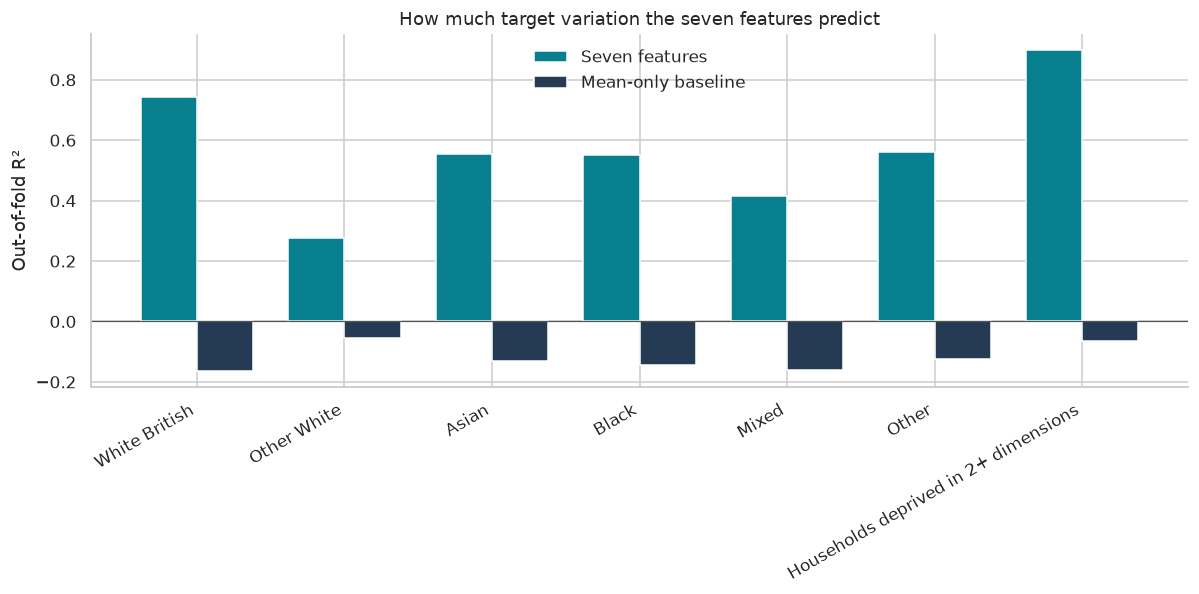

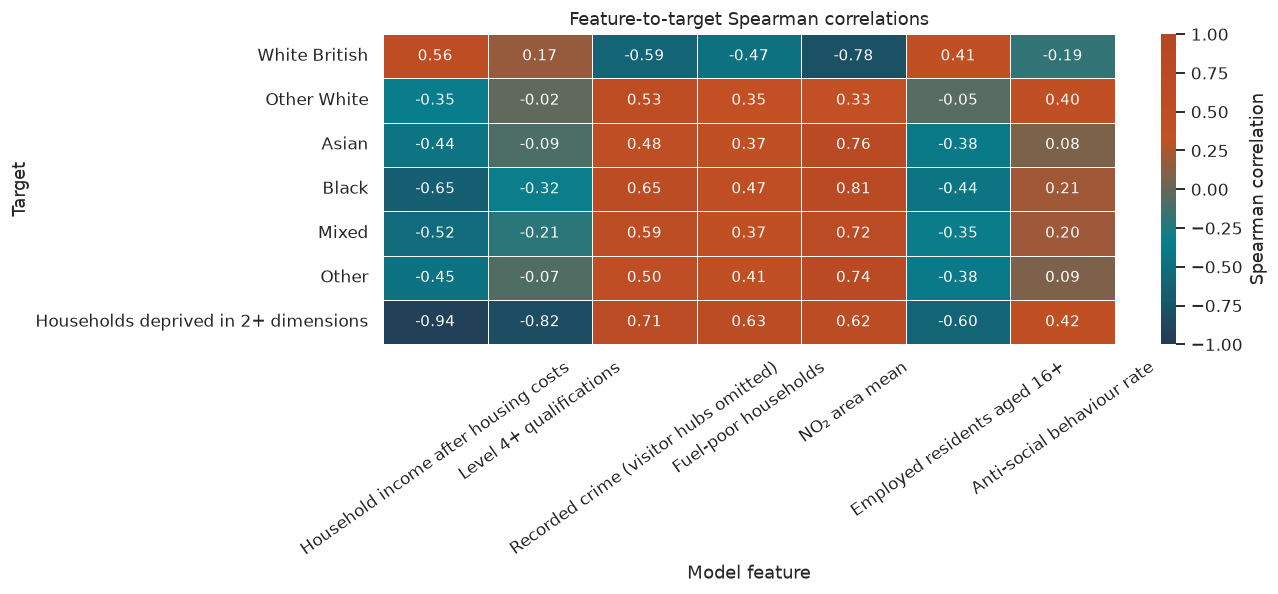

Saved proxy R² and Spearman heatmap for 7 targets and 7 features.


In [4]:
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(proxy_overlap))
width = .38
ax.bar(x - width/2, proxy_overlap["model_r2"], width, color="#087f8c", label="Seven features")
ax.bar(x + width/2, proxy_overlap["mean_only_baseline_r2"], width, color="#243b53", label="Mean-only baseline")
ax.axhline(0, color="#555555", linewidth=.8)
ax.set_xticks(x, proxy_overlap["target_label"], rotation=30, ha="right")
ax.set_ylabel("Out-of-fold R²")
ax.set_title("How much target variation the seven features predict")
ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, "proxy_r2.png")

correlation_columns = [f"spearman__{feature}" for feature in features]
heatmap = proxy_overlap.set_index("target_label")[correlation_columns].rename(
    columns={f"spearman__{f}":feature_labels[f] for f in features})
fig, ax = plt.subplots(figsize=(12, 5.5))
unit2_diverging = LinearSegmentedColormap.from_list("unit2_spearman", ["#243b53", "#087f8c", "#c25024", "#b54724"])
sns.heatmap(heatmap, vmin=-1, vmax=1, center=0, cmap=unit2_diverging, annot=True, fmt=".2f",
            linewidths=.4, cbar_kws={"label":"Spearman correlation"}, ax=ax)
ax.set_title("Feature-to-target Spearman correlations")
ax.set_xlabel("Model feature")
ax.set_ylabel("Target")
ax.tick_params(axis="x", labelrotation=35)
fig.tight_layout()
save_figure(fig, "proxy_spearman_heatmap.png")
print(f"Saved proxy R² and Spearman heatmap for {len(targets)} targets and {len(features)} features.")

## Part B — Error parity

I use the earlier model's saved out-of-fold predictions and residuals. I do not refit for this check. I split areas into low, middle and high thirds by deprivation and by combined non-White share. When values tie at a cut, area code gives a fixed order. Each interval resamples areas within its own third.

In [5]:
saved_area_results = read_csv("Cleaned/Machine Learning/area_ml_results.csv")
model_results = model_areas[["area_code", "local_area_name", "authority_name", "hle_average"]].merge(
    saved_area_results[["area_code", "out_of_fold_prediction", "residual"]],
    on="area_code", how="left", validate="one_to_one")
assert len(model_results) == EXPECTED_MODEL_AREAS
assert model_results[["out_of_fold_prediction", "residual"]].notna().all().all()
assert np.allclose(model_results["residual"],
                   model_results["hle_average"] - model_results["out_of_fold_prediction"],
                   rtol=0, atol=1e-10)
saved_metrics = {
    "rmse_years": float(np.sqrt(mean_squared_error(model_results["hle_average"], model_results["out_of_fold_prediction"]))),
    "mae_years": float(mean_absolute_error(model_results["hle_average"], model_results["out_of_fold_prediction"])),
    "r2": float(r2_score(model_results["hle_average"], model_results["out_of_fold_prediction"])),
}
for metric, value in saved_05["grouped_linear"].items():
    assert np.isclose(saved_metrics[metric], value, rtol=0, atol=1e-9), f"Saved out-of-fold {metric} differs from Notebook 05."

parity_data = model_areas[["area_code", "households_deprived_2plus_pct", "non_white_combined_pct"]].merge(
    model_results[["area_code", "residual"]], on="area_code", validate="one_to_one")
rng_bootstrap = np.random.default_rng(BOOTSTRAP_SEED)
third_names = ["Lowest third", "Middle third", "Highest third"]
error_rows = []

def bootstrap_error(residuals):
    residuals = np.asarray(residuals, dtype=float)
    sampled_positions = rng_bootstrap.integers(0, len(residuals), size=(BOOTSTRAP_RESAMPLES, len(residuals)))
    sample = residuals[sampled_positions]
    statistics = {
        "bias_years": sample.mean(axis=1),
        "mae_years": np.abs(sample).mean(axis=1),
        "rmse_years": np.sqrt(np.square(sample).mean(axis=1)),
    }
    return {
        name: (float(np.mean(values)), float(np.quantile(values, .025)), float(np.quantile(values, .975)))
        for name, values in statistics.items()
    }

for basis, measure in [
    ("deprivation", "households_deprived_2plus_pct"),
    ("combined_non_white_share", "non_white_combined_pct"),
]:
    sorted_area = parity_data.sort_values([measure, "area_code"], kind="mergesort").reset_index(drop=True)
    assert len(sorted_area) % 3 == 0
    sorted_area["third"] = np.repeat(third_names, len(sorted_area) // 3)
    assert sorted_area.groupby("third", observed=True).size().eq(len(sorted_area) // 3).all()
    for third in third_names:
        rows = sorted_area.loc[sorted_area["third"].eq(third)]
        residuals = rows["residual"].to_numpy()
        boot = bootstrap_error(residuals)
        point = {
            "bias_years": float(residuals.mean()),
            "mae_years": float(np.abs(residuals).mean()),
            "rmse_years": float(np.sqrt(np.square(residuals).mean())),
        }
        record = {"split_basis":basis, "third":third, "area_count":int(len(rows))}
        for metric in point:
            record[metric] = point[metric]
            record[f"{metric}_ci95_lower"] = boot[metric][1]
            record[f"{metric}_ci95_upper"] = boot[metric][2]
        record["bias_ci95_excludes_zero"] = bool(
            record["bias_years_ci95_lower"] > 0 or record["bias_years_ci95_upper"] < 0)
        record["model_direction"] = (
            "runs low" if point["bias_years"] > 0
            else "runs high" if point["bias_years"] < 0 else "no average bias")
        error_rows.append(record)

error_parity = pd.DataFrame(error_rows)
assert len(error_parity) == 6 and error_parity["area_count"].eq(EXPECTED_MODEL_AREAS // 3).all()
display(error_parity[[
    "split_basis", "third", "area_count",
    "bias_years", "bias_years_ci95_lower", "bias_years_ci95_upper", "bias_ci95_excludes_zero",
    "mae_years", "mae_years_ci95_lower", "mae_years_ci95_upper",
    "rmse_years", "rmse_years_ci95_lower", "rmse_years_ci95_upper",
]].round(3))

for row in error_parity.itertuples(index=False):
    direction = "low" if row.bias_years > 0 else "high" if row.bias_years < 0 else "neither high nor low"
    print(f"{row.split_basis}, {row.third}: model runs {abs(row.bias_years):.2f} years {direction}; "
          f"bias interval [{row.bias_years_ci95_lower:.2f}, {row.bias_years_ci95_upper:.2f}].")

mae_comparisons = []
for basis in error_parity["split_basis"].unique():
    subset = error_parity.loc[error_parity["split_basis"].eq(basis)].set_index("third")
    for i, first in enumerate(third_names):
        for second in third_names[i+1:]:
            left, right = subset.loc[first], subset.loc[second]
            overlap = max(0.0, min(left["mae_years_ci95_upper"], right["mae_years_ci95_upper"])
                          - max(left["mae_years_ci95_lower"], right["mae_years_ci95_lower"]))
            difference = abs(float(left["mae_years"] - right["mae_years"]))
            mae_comparisons.append({
                "split_basis":basis, "first_third":first, "second_third":second,
                "absolute_mae_difference_years":difference, "mae_interval_overlap_width_years":overlap,
                "mae_intervals_overlap":bool(overlap > 0),
                "difference_exceeds_interval_overlap":bool(difference > overlap),
            })
mae_comparisons = pd.DataFrame(mae_comparisons)
print("Pairwise MAE comparisons: a point-estimate gap is compared directly with the width shared by the two bootstrap intervals.")
display(mae_comparisons.round(3))

,split_basis,third,area_count,bias_years,bias_years_ci95_lower,bias_years_ci95_upper,bias_ci95_excludes_zero,mae_years,mae_years_ci95_lower,mae_years_ci95_upper,rmse_years,rmse_years_ci95_lower,rmse_years_ci95_upper
0,deprivation,Lowest third,218,0.306,0.099,0.524,True,1.306,1.178,1.435,1.653,1.473,1.838
1,deprivation,Middle third,218,0.146,-0.055,0.368,False,1.336,1.203,1.471,1.661,1.511,1.812
2,deprivation,Highest third,218,-0.459,-0.662,-0.252,True,1.309,1.184,1.429,1.620,1.489,1.752
3,combined_non_white_share,Lowest third,218,0.353,0.157,0.554,True,1.228,1.114,1.345,1.501,1.374,1.628
4,combined_non_white_share,Middle third,218,-0.202,-0.417,0.013,False,1.312,1.188,1.439,1.622,1.471,1.763
5,combined_non_white_share,Highest third,218,-0.157,-0.378,0.075,False,1.410,1.260,1.560,1.798,1.603,1.986


deprivation, Lowest third: model runs 0.31 years low; bias interval [0.10, 0.52].
deprivation, Middle third: model runs 0.15 years low; bias interval [-0.06, 0.37].
deprivation, Highest third: model runs 0.46 years high; bias interval [-0.66, -0.25].
combined_non_white_share, Lowest third: model runs 0.35 years low; bias interval [0.16, 0.55].
combined_non_white_share, Middle third: model runs 0.20 years high; bias interval [-0.42, 0.01].
combined_non_white_share, Highest third: model runs 0.16 years high; bias interval [-0.38, 0.07].
Pairwise MAE comparisons: a point-estimate gap is compared directly with the width shared by the two bootstrap intervals.


,split_basis,first_third,second_third,absolute_mae_difference_years,mae_interval_overlap_width_years,mae_intervals_overlap,difference_exceeds_interval_overlap
0,deprivation,Lowest third,Middle third,0.030,0.233,True,False
1,deprivation,Lowest third,Highest third,0.004,0.244,True,False
2,deprivation,Middle third,Highest third,0.026,0.226,True,False
3,combined_non_white_share,Lowest third,Middle third,0.084,0.157,True,False
4,combined_non_white_share,Lowest third,Highest third,0.182,0.085,True,True
5,combined_non_white_share,Middle third,Highest third,0.098,0.179,True,False


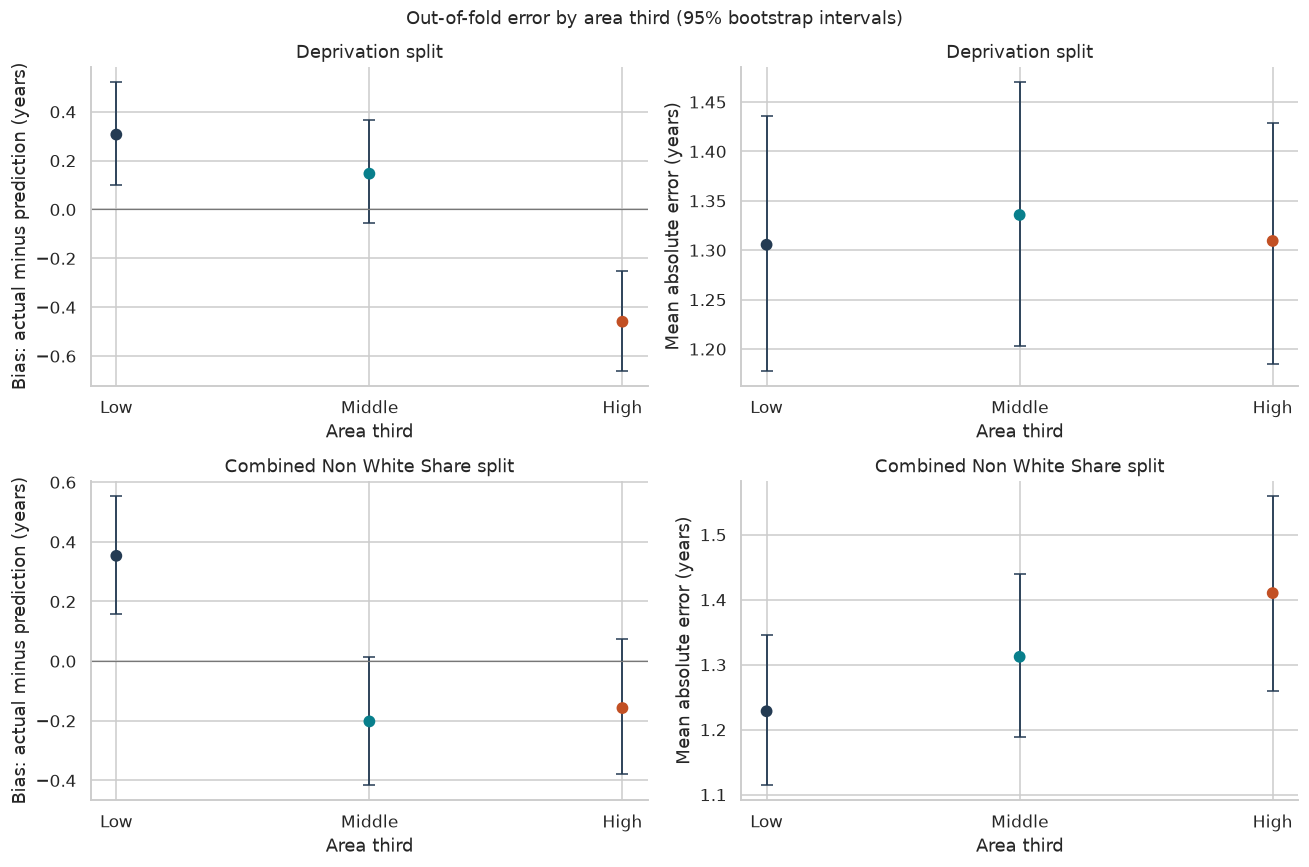

Saved bias and absolute-error comparisons with within-third bootstrap intervals.


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
metric_specs = [
    ("bias_years", "Bias: actual minus prediction (years)"),
    ("mae_years", "Mean absolute error (years)"),
]
colors = ["#243b53", "#087f8c", "#c25024"]
for column, (metric, label) in enumerate(metric_specs):
    for row, basis in enumerate(["deprivation", "combined_non_white_share"]):
        ax = axes[row, column]
        subset = error_parity.loc[error_parity["split_basis"].eq(basis)].set_index("third").loc[third_names]
        values = subset[metric].to_numpy()
        lows = values - subset[f"{metric}_ci95_lower"].to_numpy()
        highs = subset[f"{metric}_ci95_upper"].to_numpy() - values
        x = np.arange(3)
        ax.errorbar(x, values, yerr=np.vstack([lows, highs]), fmt="none",
                    ecolor="#243b53", capsize=4, linewidth=1.2)
        ax.scatter(x, values, c=colors, s=45, zorder=3)
        ax.set_xticks(x, ["Low", "Middle", "High"])
        ax.set_xlabel("Area third")
        ax.set_ylabel(label)
        ax.set_title(f"{basis.replace('_', ' ').title()} split")
        if metric == "bias_years":
            ax.axhline(0, color="#777777", linewidth=.8)
fig.suptitle("Out-of-fold error by area third (95% bootstrap intervals)")
fig.tight_layout()
save_figure(fig, "error_by_third_intervals.png")
print("Saved bias and absolute-error comparisons with within-third bootstrap intervals.")

## Part C — Crime sensitivity

I refit the grouped cross-validation after removing crime, keeping the same areas, authority folds, scaling pipeline and seed. I compare the saved seven-feature model with the six-feature result. The neighbour calculation and permutation settings match Notebook 05.

In [7]:
crime_free_features = [feature for feature in features if feature != "crime_for_analysis"]
assert len(crime_free_features) == 6
y_hle = model_areas["hle_average"].to_numpy(dtype=float)
predictions_without_crime = np.full(len(model_areas), np.nan)
for training, test in cv_folds:
    assert not (set(cv_groups[training]) & set(cv_groups[test]))
    model = Pipeline([("scale", StandardScaler()), ("linear", LinearRegression())])
    model.fit(model_areas[crime_free_features].iloc[training], y_hle[training])
    predictions_without_crime[test] = model.predict(model_areas[crime_free_features].iloc[test])
assert np.isfinite(predictions_without_crime).all()

predictions_with_crime = model_results["out_of_fold_prediction"].to_numpy()
residuals_with_crime = model_results["residual"].to_numpy()
residuals_without_crime = y_hle - predictions_without_crime

def prediction_metrics(actual, prediction):
    return {
        "rmse_years":float(np.sqrt(mean_squared_error(actual, prediction))),
        "mae_years":float(mean_absolute_error(actual, prediction)),
        "r2":float(r2_score(actual, prediction)),
    }
metrics_with_crime = prediction_metrics(y_hle, predictions_with_crime)
metrics_without_crime = prediction_metrics(y_hle, predictions_without_crime)
for metric, value in saved_05["grouped_linear"].items():
    assert np.isclose(metrics_with_crime[metric], value, rtol=0, atol=1e-9)

all_pairs = read_csv("Cleaned/Neighbours/neighbour_pairs.csv")
included_codes = pd.Index(model_areas["area_code"])
restricted_pairs = all_pairs.loc[
    all_pairs["area_a"].isin(included_codes) & all_pairs["area_b"].isin(included_codes)
].copy()
a_index = included_codes.get_indexer(restricted_pairs["area_a"])
b_index = included_codes.get_indexer(restricted_pairs["area_b"])
assert (a_index >= 0).all() and (b_index >= 0).all()
n_areas = len(model_areas)
adjacency = np.zeros((n_areas, n_areas), dtype=float)
adjacency[a_index, b_index] = adjacency[b_index, a_index] = 1
degree = adjacency.sum(axis=1)
assert (degree > 0).all()
weights = adjacency / degree[:, None]
assert len(restricted_pairs) == saved_05["retained_neighbour_pairs"]

def moran_reference(values):
    centred = np.asarray(values) - np.mean(values)
    denominator = float(centred @ centred)
    observed = float(n_areas / weights.sum() * (centred @ weights @ centred) / denominator)
    rng = np.random.default_rng(SEED)
    permutation_i = np.empty(MORAN_PERMUTATIONS)
    for start in range(0, MORAN_PERMUTATIONS, 100):
        stop = min(start + 100, MORAN_PERMUTATIONS)
        shuffled = np.stack([rng.permutation(centred) for _ in range(stop - start)])
        permutation_i[start:stop] = (
            n_areas / weights.sum()
            * np.sum(shuffled * (shuffled @ weights.T), axis=1)
            / denominator
        )
    return {
        "moran_i":observed,
        "permutation_mean":float(permutation_i.mean()),
        "positive_permutation_reference":float(
            (1 + np.sum(permutation_i >= observed)) / (MORAN_PERMUTATIONS + 1)
        ),
    }

moran_with_crime = moran_reference(residuals_with_crime)
moran_without_crime = moran_reference(residuals_without_crime)
for key, value in saved_05["residual_moran"].items():
    assert np.isclose(moran_with_crime[key], value, rtol=0, atol=1e-9), f"Notebook 05 Moran value differs: {key}."

prediction_changes = model_areas[["area_code", "local_area_name", "authority_name"]].copy()
prediction_changes["prediction_with_crime_years"] = predictions_with_crime
prediction_changes["prediction_without_crime_years"] = predictions_without_crime
prediction_changes["change_without_minus_with_crime_years"] = predictions_without_crime - predictions_with_crime
prediction_changes["absolute_prediction_change_years"] = prediction_changes[
    "change_without_minus_with_crime_years"
].abs()
crime_prediction_changes = prediction_changes.sort_values(
    ["absolute_prediction_change_years", "area_code"], ascending=[False, True], kind="mergesort"
).head(10).reset_index(drop=True)

coefficient_model_7 = Pipeline([("scale", StandardScaler()), ("linear", LinearRegression())]).fit(
    model_areas[features], y_hle)
coefficient_model_6 = Pipeline([("scale", StandardScaler()), ("linear", LinearRegression())]).fit(
    model_areas[crime_free_features], y_hle)
saved_coefficients = read_csv("Cleaned/Machine Learning/coefficients.csv").set_index("measure")
coef_7 = pd.Series(coefficient_model_7.named_steps["linear"].coef_, index=features)
np.testing.assert_allclose(
    coef_7.reindex(saved_coefficients.index).to_numpy(),
    saved_coefficients["standardised_coefficient_years"].to_numpy(),
    rtol=0, atol=1e-9,
)
coef_6 = pd.Series(coefficient_model_6.named_steps["linear"].coef_, index=crime_free_features)
coefficient_rows = []
for feature in crime_free_features:
    coefficient_rows.append({
        "feature":feature, "feature_label":feature_labels[feature],
        "standardised_coefficient_with_crime_years":float(coef_7[feature]),
        "standardised_coefficient_without_crime_years":float(coef_6[feature]),
        "coefficient_change_without_minus_with_years":float(coef_6[feature] - coef_7[feature]),
    })

crime_sensitivity_rows = []
for model_name, count, metrics, moran in [
    ("Seven features including crime", 7, metrics_with_crime, moran_with_crime),
    ("Six features without crime", 6, metrics_without_crime, moran_without_crime),
]:
    crime_sensitivity_rows.append({
        "record_type":"model_metrics", "model":model_name, "feature_count":count,
        "area_count":len(model_areas), **metrics,
        "residual_moran_i":moran["moran_i"],
        "moran_permutation_mean":moran["permutation_mean"],
        "moran_positive_permutation_reference":moran["positive_permutation_reference"],
    })
crime_sensitivity_rows.append({
    "record_type":"metric_change", "model":"Six features minus seven features",
    "feature_count":-1, "area_count":len(model_areas),
    "rmse_years":metrics_without_crime["rmse_years"] - metrics_with_crime["rmse_years"],
    "mae_years":metrics_without_crime["mae_years"] - metrics_with_crime["mae_years"],
    "r2":metrics_without_crime["r2"] - metrics_with_crime["r2"],
    "residual_moran_i":moran_without_crime["moran_i"] - moran_with_crime["moran_i"],
    "moran_permutation_mean":moran_without_crime["permutation_mean"] - moran_with_crime["permutation_mean"],
    "moran_positive_permutation_reference":np.nan,
})
for row in coefficient_rows:
    crime_sensitivity_rows.append({
        "record_type":"standardised_coefficient", "model":"Full-data coefficient comparison",
        "feature_count":6, "area_count":len(model_areas), "feature":row["feature"],
        "feature_label":row["feature_label"],
        "standardised_coefficient_with_crime_years":row["standardised_coefficient_with_crime_years"],
        "standardised_coefficient_without_crime_years":row["standardised_coefficient_without_crime_years"],
        "coefficient_change_without_minus_with_years":row["coefficient_change_without_minus_with_years"],
    })
crime_sensitivity = pd.DataFrame(crime_sensitivity_rows)

display(crime_sensitivity.loc[crime_sensitivity["record_type"].eq("model_metrics"), [
    "model", "feature_count", "area_count", "rmse_years", "mae_years", "r2",
    "residual_moran_i", "moran_positive_permutation_reference",
]].round(4))
display(pd.DataFrame(coefficient_rows).round(4))
display(crime_prediction_changes.round(3))

,model,feature_count,area_count,rmse_years,mae_years,r2,residual_moran_i,moran_positive_permutation_reference
0,Seven features including crime,7,654,1.6448,1.3168,0.8937,0.1541,0.001
1,Six features without crime,6,654,1.6548,1.3286,0.8924,0.1703,0.001


,feature,feature_label,standardised_coefficient_with_crime_years,standardised_coefficient_without_crime_years,coefficient_change_without_minus_with_years
0,annual_equivalised_income_after_housing_costs_gbp,Household income after housing costs,3.0994,3.2028,0.1033
1,level4plus_pct,Level 4+ qualifications,1.1119,1.0536,-0.0583
2,fuel_poor_households_pct,Fuel-poor households,-0.3044,-0.3593,-0.0549
3,no2_area_mean_ug_m3,NO₂ area mean,-0.6144,-0.7838,-0.1694
4,employed_residents_16plus_pct,Employed residents aged 16+,-0.1881,-0.2117,-0.0236
5,asb_rows_per_1000_residents,Anti-social behaviour rate,-0.2025,-0.4464,-0.2438


,area_code,local_area_name,authority_name,prediction_with_crime_years,prediction_without_crime_years,change_without_minus_with_crime_years,absolute_prediction_change_years
0,E02002089,Marston Green,Solihull,61.896,64.273,2.376,2.376
1,E02002061,Greets Green East,Sandwell,54.650,56.331,1.681,1.681
2,E02002099,Central Solihull,Solihull,68.302,69.833,1.531,1.531
3,E02002021,Brierley Hill,Dudley,56.128,57.327,1.199,1.199
4,E02006481,Stockingford,Nuneaton and Bedworth,60.971,59.900,-1.072,1.072
5,E02006197,Central Stafford,Stafford,59.956,60.982,1.026,1.026
6,E02006487,Bedworth Town,Nuneaton and Bedworth,59.735,58.805,-0.929,0.929
7,E02002047,Wednesbury,Sandwell,58.082,58.956,0.874,0.874
8,E02006218,Central Tamworth,Tamworth,60.714,61.566,0.851,0.851
9,E02005406,Coalville,North West Leicestershire,61.669,62.493,0.824,0.824


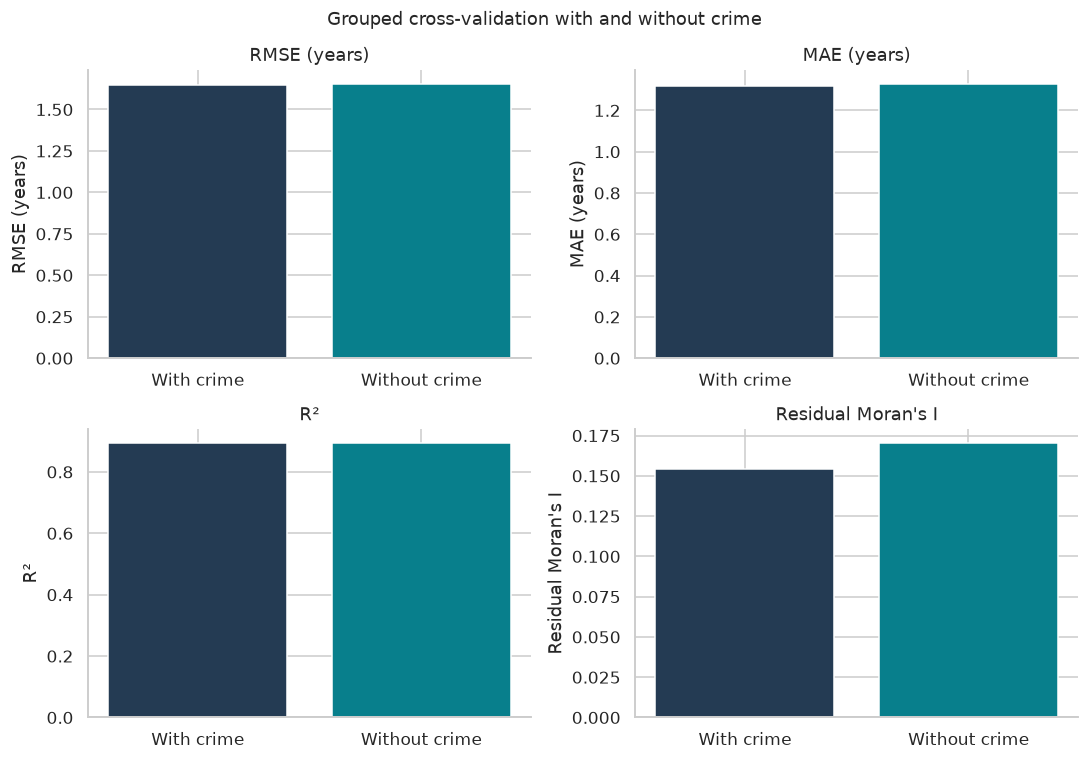

Saved the four-metric comparison; the tables also show the ten largest prediction changes and shared coefficients.


In [8]:
metrics_rows = crime_sensitivity.loc[crime_sensitivity["record_type"].eq("model_metrics")].set_index("model")
metric_names = [
    ("rmse_years", "RMSE (years)"),
    ("mae_years", "MAE (years)"),
    ("r2", "R²"),
    ("residual_moran_i", "Residual Moran's I"),
]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (metric, label) in zip(axes.flat, metric_names):
    values = [metrics_rows.loc["Seven features including crime", metric],
              metrics_rows.loc["Six features without crime", metric]]
    ax.bar(["With crime", "Without crime"], values, color=["#243b53", "#087f8c"])
    ax.set_title(label)
    ax.set_ylabel(label)
fig.suptitle("Grouped cross-validation with and without crime")
fig.tight_layout()
save_figure(fig, "crime_with_without_comparison.png")
print("Saved the four-metric comparison; the tables also show the ten largest prediction changes and shared coefficients.")

## Saving the outputs

I save proxy metrics and correlations, parity estimates with bootstrap intervals, the crime comparison and the largest prediction changes. The data dictionary covers every CSV column and every JSON leaf.

In [9]:
error_dictionary = {
    "split_basis":("text","Measure used to split the modelling areas"),
    "third":("category","Low, middle or high third of the split measure"),
    "area_count":("areas","Areas in this third"),
    "bias_years":("years","Mean residual; actual HLE minus out-of-fold prediction"),
    "mae_years":("years","Mean absolute out-of-fold residual"),
    "rmse_years":("years","Root mean square out-of-fold residual"),
    "bias_years_ci95_lower":("years","Lower percentile bootstrap bound for mean residual"),
    "bias_years_ci95_upper":("years","Upper percentile bootstrap bound for mean residual"),
    "mae_years_ci95_lower":("years","Lower percentile bootstrap bound for MAE"),
    "mae_years_ci95_upper":("years","Upper percentile bootstrap bound for MAE"),
    "rmse_years_ci95_lower":("years","Lower percentile bootstrap bound for RMSE"),
    "rmse_years_ci95_upper":("years","Upper percentile bootstrap bound for RMSE"),
    "bias_ci95_excludes_zero":("boolean","Whether the 95% bias interval lies entirely above or below zero"),
    "model_direction":("text","Whether positive residuals mean the model runs low or high"),
}
crime_dictionary = {
    "record_type":("category","Model metrics, metric change or standardised coefficient"),
    "model":("text","Model or comparison named in this row"),
    "feature_count":("features","Number of predictors; negative one denotes a difference row"),
    "area_count":("areas","Model areas used"),
    "rmse_years":("years","Out-of-fold root mean square error; difference row is without minus with crime"),
    "mae_years":("years","Out-of-fold mean absolute error; difference row is without minus with crime"),
    "r2":("fraction","Out-of-fold R-squared; difference row is without minus with crime"),
    "residual_moran_i":("Moran's I","Moran's I for saved or refitted out-of-fold residuals"),
    "moran_permutation_mean":("Moran's I","Mean of the seeded permutation reference"),
    "moran_positive_permutation_reference":("fraction 0–1","Plus-one share of shuffled residual maps at least as high as observed"),
    "feature":("identifier","Shared model feature for coefficient rows"),
    "feature_label":("text","Readable feature label"),
    "standardised_coefficient_with_crime_years":("years per SD","Full-data standardised coefficient in the seven-feature model"),
    "standardised_coefficient_without_crime_years":("years per SD","Full-data standardised coefficient without crime"),
    "coefficient_change_without_minus_with_years":("years per SD","No-crime coefficient minus seven-feature coefficient"),
}
change_dictionary = {
    "area_code":("MSOA21 identifier","Unique area code"),
    "local_area_name":("text","Familiar name of the area"),
    "authority_name":("local authority","Authority held out together in cross-validation"),
    "prediction_with_crime_years":("years","Saved Notebook 05 out-of-fold prediction"),
    "prediction_without_crime_years":("years","Out-of-fold prediction from the six-feature refit"),
    "change_without_minus_with_crime_years":("years","No-crime prediction minus saved prediction"),
    "absolute_prediction_change_years":("years","Absolute change in predicted HLE"),
}
proxy_dictionary = {
    "target":("identifier","Six-group ethnic share or deprivation measure"),
    "target_label":("text","Readable target name"),
    "target_group":("category","Ethnicity or deprivation"),
    "area_count":("areas","Areas in grouped cross-validation"),
    "model_r2":("fraction","Out-of-fold R-squared for seven-feature prediction"),
    "model_mae_percentage_points":("percentage points","Out-of-fold mean absolute error for seven-feature prediction"),
    "mean_only_baseline_r2":("fraction","Out-of-fold R-squared for fold training-mean baseline"),
    "mean_only_baseline_mae_percentage_points":("percentage points","Out-of-fold mean absolute error for fold training-mean baseline"),
}
for feature in features:
    proxy_dictionary[f"spearman__{feature}"] = ("Spearman rho", f"Spearman correlation between {feature_labels[feature]} and the target")

dictionary_rows = []
for filename, table, definitions in [
    ("proxy_overlap.csv", proxy_overlap, proxy_dictionary),
    ("error_parity.csv", error_parity, error_dictionary),
    ("crime_sensitivity.csv", crime_sensitivity, crime_dictionary),
    ("crime_prediction_changes.csv", crime_prediction_changes, change_dictionary),
]:
    for column in table.columns:
        unit, meaning = definitions[column]
        dictionary_rows.append({"file":filename, "column":column, "meaning":meaning,
                                "unit":unit, "missing_rule":"Blank where the field does not apply"})

summary = {
    "source_area_count": EXPECTED_AREAS,
    "modelling_area_count": int(len(model_areas)),
    "features": features,
    "folds": FOLDS,
    "seed": SEED,
    "held_out_groups": "Local authority; GroupKFold; same test authorities as Notebook 05.",
    "ethnicity_group_definition": ethnicity_sources,
    "combined_non_white_definition": "Sum of Asian, Black, Mixed and Other. Other White (White Irish, Gypsy or Irish Traveller, Roma and Other White) is classified as White and excluded.",
    "proxy_overlap": proxy_overlap.to_dict("records"),
    "error_parity": error_parity.to_dict("records"),
    "bootstrap_resamples_per_third": BOOTSTRAP_RESAMPLES,
    "bootstrap_seed": BOOTSTRAP_SEED,
    "bootstrap_interval": "Percentile 95% interval; areas resampled with replacement within each third.",
    "mae_pairwise_comparisons": mae_comparisons.to_dict("records"),
    "mae_comparison_rule": "Compare the absolute point-estimate gap with the width shared by the two percentile intervals.",
    "saved_notebook_05_metrics": saved_metrics,
    "crime_sensitivity": {
        "models": [
            {"model":"Seven features including crime", "feature_count":7, **metrics_with_crime, **moran_with_crime},
            {"model":"Six features without crime", "feature_count":6, **metrics_without_crime, **moran_without_crime},
        ],
        "changes_without_minus_with": {
            "rmse_years":metrics_without_crime["rmse_years"] - metrics_with_crime["rmse_years"],
            "mae_years":metrics_without_crime["mae_years"] - metrics_with_crime["mae_years"],
            "r2":metrics_without_crime["r2"] - metrics_with_crime["r2"],
            "residual_moran_i":moran_without_crime["moran_i"] - moran_with_crime["moran_i"],
        },
        "shared_feature_coefficients":coefficient_rows,
    },
    "crime_prediction_changes": crime_prediction_changes.to_dict("records"),
    "crime_free_features": crime_free_features,
    "moran_neighbour_pair_count": int(len(restricted_pairs)),
    "moran_permutations": MORAN_PERMUTATIONS,
    "moran_seed": SEED,
    "output_folder": output_folder.relative_to(project_folder).as_posix(),
}

def flatten_json(value, prefix=""):
    if isinstance(value, dict):
        for key, child in value.items():
            yield from flatten_json(child, f"{prefix}.{key}" if prefix else str(key))
    elif isinstance(value, list):
        if value:
            for child in value:
                yield from flatten_json(child, f"{prefix}[]")
        else:
            yield prefix, []
    else:
        yield prefix, value

summary_descriptions = {
    "source_area_count":("areas","Source MSOA areas"),
    "modelling_area_count":("areas","Complete-case model areas"),
    "folds":("folds","Number of local-authority GroupKFold splits"),
    "seed":("seed","Notebook 05 random seed"),
    "bootstrap_resamples_per_third":("resamples","Bootstrap samples generated within each third"),
    "bootstrap_seed":("seed","Fixed bootstrap generator seed"),
    "moran_neighbour_pair_count":("pairs","Shared-edge pairs retained after modelling-area exclusions"),
    "moran_permutations":("permutations","Number of Moran reference permutations"),
    "moran_seed":("seed","Seed used for Moran reference permutations"),
    "output_folder":("project-relative path","Folder containing this notebook's outputs"),
}
added_summary_keys = set()
for key, value in flatten_json(summary):
    if key in added_summary_keys:
        continue
    added_summary_keys.add(key)
    if key in summary_descriptions:
        unit, meaning = summary_descriptions[key]
    elif key.startswith("proxy_overlap[].spearman__"):
        unit, meaning = ("Spearman rho","Out-of-fold area target's rank correlation with the named model feature")
    elif key.startswith("proxy_overlap[]."):
        unit, meaning = ("value","Proxy prediction metric or target definition recorded for a row")
    elif key.startswith("error_parity[]."):
        unit, meaning = ("value","Third-specific error estimate or bootstrap interval value")
    elif key.startswith("mae_pairwise_comparisons[]."):
        unit, meaning = ("value","Pairwise MAE point-gap and confidence-interval overlap comparison")
    elif key.startswith("crime_sensitivity[]."):
        unit, meaning = ("value","Crime sensitivity model metric or coefficient comparison")
    elif key.startswith("crime_prediction_changes[]."):
        unit, meaning = ("value","Area-level change between saved and no-crime predictions")
    else:
        unit, meaning = ("text or rule","Recorded model feature, assumption, method or definition")
    dictionary_rows.append({"file":"results_summary.json","column":key,"meaning":meaning,
                            "unit":unit,"missing_rule":"JSON null only where the value does not apply"})
for column, (unit, meaning) in {
    "file":("text","Filename described by this row"),
    "column":("text","CSV column or dotted JSON path; [] marks repeated items"),
    "meaning":("text","What the field records"),
    "unit":("text","Measurement unit or value type"),
    "missing_rule":("text","Meaning of a blank value"),
}.items():
    dictionary_rows.append({"file":"data_dictionary.csv","column":column,"meaning":meaning,
                            "unit":unit,"missing_rule":"No missing values"})

data_dictionary = pd.DataFrame(dictionary_rows)
assert not data_dictionary.duplicated(["file","column"]).any()
for filename, table in [
    ("proxy_overlap.csv",proxy_overlap), ("error_parity.csv",error_parity),
    ("crime_sensitivity.csv",crime_sensitivity), ("crime_prediction_changes.csv",crime_prediction_changes),
]:
    assert set(data_dictionary.loc[data_dictionary["file"].eq(filename), "column"]) == set(table.columns)
assert set(data_dictionary.loc[data_dictionary["file"].eq("results_summary.json"), "column"]) == {
    key for key,_ in flatten_json(summary)
}
save_csv(proxy_overlap, "proxy_overlap.csv")
save_csv(error_parity, "error_parity.csv")
save_csv(crime_sensitivity, "crime_sensitivity.csv")
save_csv(crime_prediction_changes, "crime_prediction_changes.csv")
save_json(summary, "results_summary.json")
save_csv(data_dictionary, "data_dictionary.csv")
print(f"Saved {len(proxy_overlap)} proxy targets, {len(error_parity)} parity groups, "
      f"{len(crime_prediction_changes)} largest prediction changes, {len(list(figure_folder.glob('*.png')))} figures and dictionary.")

Saved 7 proxy targets, 6 parity groups, 10 largest prediction changes, 4 figures and dictionary.


In [10]:
print("Ethics questions addressed: Q7, Q15 and Q11.")
print("Proxy target R-squared and error metrics:"); display(proxy_overlap[metric_columns].round(3))
print("Bias intervals excluding zero:", int(error_parity["bias_ci95_excludes_zero"].sum()), "of", len(error_parity))
print("MAE comparisons whose point gap exceeds interval overlap:",
      int(mae_comparisons["difference_exceeds_interval_overlap"].sum()), "of", len(mae_comparisons))
print("Grouped model with crime:", metrics_with_crime, moran_with_crime)
print("Grouped model without crime:", metrics_without_crime, moran_without_crime)

Ethics questions addressed: Q7, Q15 and Q11.
Proxy target R-squared and error metrics:


,target_label,model_r2,model_mae_percentage_points,mean_only_baseline_r2,mean_only_baseline_mae_percentage_points
0,White British,0.743,9.517,-0.165,20.984
1,Other White,0.277,2.050,-0.055,2.500
2,Asian,0.554,7.952,-0.131,12.861
3,Black,0.550,2.512,-0.145,4.435
4,Mixed,0.414,0.916,-0.162,1.440
5,Other,0.562,1.047,-0.123,1.884
6,Households deprived in 2+ dimensions,0.898,1.788,-0.066,6.501


Bias intervals excluding zero: 3 of 6
MAE comparisons whose point gap exceeds interval overlap: 1 of 6
Grouped model with crime: {'rmse_years': 1.6447959118176452, 'mae_years': 1.3168409287295222, 'r2': 0.8937396887082472} {'moran_i': 0.15412637854835512, 'permutation_mean': -0.0016655073892266074, 'positive_permutation_reference': 0.001}
Grouped model without crime: {'rmse_years': 1.6548006190439002, 'mae_years': 1.3286171128538782, 'r2': 0.8924430700386533} {'moran_i': 0.17030035571359547, 'permutation_mean': -0.00181853845197933, 'positive_permutation_reference': 0.001}


## What this means ethically

For Q7, the proxy results show how much the model features carry information about the six ethnic-composition measures and deprivation. I report that overlap as a finding; I do not remove features because they predict these area-level measures.

For Q15, the bias intervals and absolute-error comparisons show where the saved model runs high or low and whether error differs across the defined thirds. For Q11, the crime sensitivity check shows whether predictions change when the recorded-crime measure is removed. These are tests of association and model behaviour, not causes or claims about individuals.